In [1]:
import os
from pathlib import Path

os.environ["NJ_DOMAIN"] = "v4_refreeze"  # must precede the nj_sfincs import

import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "nj_sfincs").is_dir())
sys.path.insert(0, str(ROOT))

import logging
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pyproj import Transformer

from nj_sfincs import domain, plots

warnings.filterwarnings("ignore")
logging.disable(logging.ERROR)  # hydromt chatter (binary ini, region component)

DOM = domain.active()
EXP = ROOT / "experiments" / DOM.name
MARKS = ROOT / "reports" / "v4_first_results_2026-10-09" / "marks"  # canonical per-mark scores
PREMIER, TWIN = "naccs-premier", "naccs-nowaves"  # NACCS-blend wind (re-baselined 10-11)
ERA5 = "_pre_rebaseline_2026-10-11/naccs-premier"  # the parked ERA5-wind premier
LAKE_MARKS = [6130, 6121, 6122, 6124, 6129]  # coastal lakes the sea never reaches in the model

SURFACE, INK, INK_2, GREY, ORANGE = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c3", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 9,
                     "axes.edgecolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2})

g = xr.open_dataset(EXP / "_template_sealed" / "sfincs.nc")
FX, FY = g["mesh2d_face_x"].values, g["mesh2d_face_y"].values
MASK, LEV = g["mask"].values, g["level"].values
SIZE = np.round(float(g.attrs["dx"]) / 2.0 ** (LEV - 1))
with xr.open_dataset(EXP / PREMIER / "sfincs_subgrid.nc") as s:
    ZMIN = s["z_zmin"].values
ACT = MASK > 0

TO_UTM = Transformer.from_crs(4326, DOM.epsg, always_xy=True)
RING4 = gpd.read_file(DOM.region).to_crs(DOM.epsg)
RING3 = gpd.read_file(domain.DOMAINS["v3"].region).to_crs(DOM.epsg)
NJ = plots.state_outline(DOM.epsg)
_line = domain.read_waterlevel_line(DOM.waterlevel_line)
LX, LY = TO_UTM.transform([p[1] for p in _line], [p[2] for p in _line])
WIN = (434_000, 628_000, 4_283_000, 4_540_000)
NYB = (548_000, 600_000, 4_462_000, 4_502_000)  # NY bays / Raritan inset


def binned(x, y, v, res, win=WIN, how="max"):
    x0, x1, y0, y1 = win
    nx, ny = int((x1 - x0) / res), int((y1 - y0) / res)
    c, r = ((x - x0) / res).astype(int), ((y1 - y) / res).astype(int)
    ok = (c >= 0) & (c < nx) & (r >= 0) & (r < ny) & np.isfinite(v)
    out = np.full((ny, nx), np.nan)
    vals = pd.Series(v[ok]).groupby(r[ok] * nx + c[ok])
    agg = getattr(vals, how)()
    out.flat[agg.index.values] = agg.values
    return out, (x0, x1, y0, y1)


def frame(ax, win=WIN, ring=True, line=True):
    NJ.plot(ax=ax, color=INK_2, lw=0.5, alpha=0.45)
    if ring:
        RING4.boundary.plot(ax=ax, color=INK_2, lw=0.6)
    if line:
        ax.plot(LX, LY, color=INK, lw=1.0)
    ax.set_xlim(win[0], win[1]); ax.set_ylim(win[2], win[3])
    ax.set_aspect(1); ax.set_xticks([]); ax.set_yticks([])


def peak(run):
    with xr.open_dataset(EXP / run / "sfincs_map.nc") as m:
        zs = m["zsmax"].max("timemax").values
    wet = ACT & np.isfinite(zs) & (zs - ZMIN > 0.10) & (ZMIN < 6.0)
    return np.where(wet, zs, np.nan)


def peak_sea(run, rain_off="naccs-nowaves+rain-off+slr-0m"):
    """Peak water level where the SEA or a river reaches: wet in the rain-off run, or bed < 2 m.

    Rain ponding on high ground (beds 3–6 m on the Delaware shore) would otherwise read as
    a 4 m+ "peak water level"."""
    zs, ro = peak(run), peak(rain_off)
    return np.where(np.isfinite(ro) | (ZMIN < 2.0), zs, np.nan)


def marks(label):
    m = pd.read_csv(MARKS / f"{label}.csv")
    m = m[m["scored"]].copy()
    m["model_m"] = m["elev_m"] + m["resid_m"]
    return m.set_index("hwm_id")


def rmse(r):
    return float(np.sqrt(np.mean(np.square(r))))


def paired_ci(ra, rb, n_boot=20_000, seed=20261007):
    """RMSE(a) − RMSE(b) on the SAME marks, bootstrapped over marks (as paired_hwm_bootstrap)."""
    a, b = np.asarray(ra), np.asarray(rb)
    idx = np.random.default_rng(seed).integers(0, len(a), (n_boot, len(a)))
    d = np.sqrt((a[idx] ** 2).mean(1)) - np.sqrt((b[idx] ** 2).mean(1))
    return rmse(a) - rmse(b), *np.percentile(d, [2.5, 97.5])


GROUPS = {
    "open coast": ("atlantic_oceanfront", "south_coast", "lbi_barrier", "absecon_atlantic_city",
                   "cape_may", "barnegat_barrier"),
    "inlets": ("manasquan", "shark_river", "great_egg"),
    "NY bays": ("raritan_bay", "sandy_hook_bay", "shrewsbury_navesink", "lower_bay_si_shore",
                "brooklyn_breezy"),
    "NJ back bays": ("cape_may_back_bays", "great_bay_mullica", "barnegat_bay"),
    "rivers / Newark Bay": ("raritan_river", "arthur_kill_nj", "newark_bay", "delaware_river",
                            "delaware_river_upper"),
    "Delaware Bay": ("delaware_bay_shore", "delaware_bay_de", "delaware_bay_nj_upper"),
}
GROUP_OF = {b: k for k, bs in GROUPS.items() for b in bs}
GROUP_COLOR = dict(zip(GROUPS, ["#1b4f96", "#3f8ad6", "#eb6834", "#2a9d8f", "#8e5ea2", "#b8860b"]))

METRICS = pd.read_csv(EXP / "metrics.csv", index_col=0)
P = METRICS.loc[PREMIER]
_r = marks("rfw_on")["resid_m"]  # same run, renamed 10-11 — must reproduce the metrics row
assert abs(rmse(_r) - P["hwm_rmse_scored_m"]) < 1e-4 and abs(_r.mean() - P["hwm_bias_scored_m"]) < 1e-4
print(DOM.name, "| active faces", f"{ACT.sum():,}", "| premier HWM RMSE",
      f"{P['hwm_rmse_scored_m']:.3f} m (median, {P['hwm_radius_m']:.0f} m, n {P['hwm_n_scored']:.0f})")


v4_refreeze | active faces 3,965,303 | premier HWM RMSE 0.436 m (median, 50 m, n 110)


## The v4 domain and its mesh

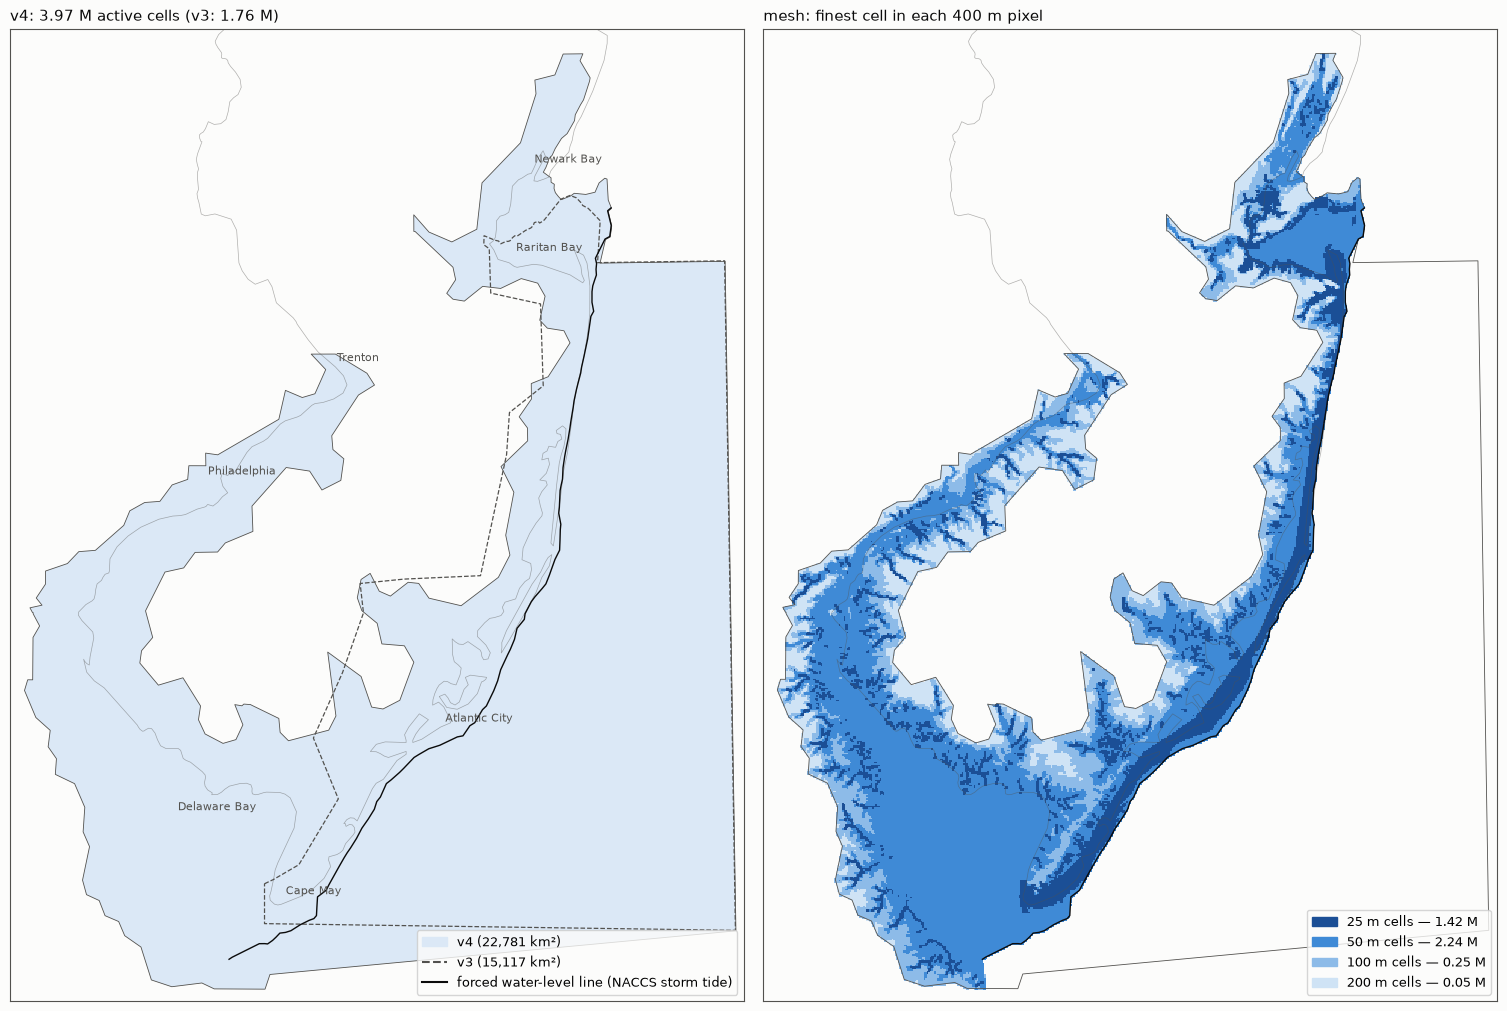

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 10), constrained_layout=True)
RING4.plot(ax=a, color="#dbe8f6", edgecolor=INK_2, lw=0.6)
RING3.boundary.plot(ax=a, color=INK_2, lw=0.9, ls="--")
frame(a, ring=False)
for lab, lon, lat in [("Delaware Bay", -75.25, 39.15), ("Trenton", -74.76, 40.22),
                      ("Philadelphia", -75.16, 39.95), ("Newark Bay", -74.14, 40.69),
                      ("Raritan Bay", -74.20, 40.48), ("Atlantic City", -74.43, 39.36),
                      ("Cape May", -74.92, 38.95)]:
    x, y = TO_UTM.transform(lon, lat)
    a.text(x, y, lab, fontsize=8, color=INK_2)
a.legend(handles=[
    Patch(color="#dbe8f6", label=f"v4 ({RING4.to_crs(6933).area.sum() / 1e6:,.0f} km²)"),
    Line2D([], [], color=INK_2, ls="--", label=f"v3 ({RING3.to_crs(6933).area.sum() / 1e6:,.0f} km²)"),
    Line2D([], [], color=INK, label="forced water-level line (NACCS storm tide)"),
], loc="lower right", facecolor=SURFACE)
a.set_title(f"v4: {ACT.sum() / 1e6:.2f} M active cells (v3: 1.76 M)", loc="left", color=INK)

img, ext = binned(FX[ACT], FY[ACT], SIZE[ACT], 400.0, how="min")
cmap = ListedColormap(["#1b4f96", "#3f8ad6", "#8dbbe8", "#cfe3f5"])
norm = BoundaryNorm([0, 37.5, 75, 150, 300], cmap.N)
b.imshow(img, extent=ext, cmap=cmap, norm=norm, interpolation="nearest")
frame(b)
counts = {s: int((ACT & (SIZE == s)).sum()) for s in (25, 50, 100, 200)}
b.legend(handles=[Patch(color=cmap(norm(s)), label=f"{s} m cells — {n / 1e6:.2f} M")
                  for s, n in counts.items()], loc="lower right", facecolor=SURFACE)
b.set_title("mesh: finest cell in each 400 m pixel", loc="left", color=INK);


## Peak water level in Sandy — v4 premier

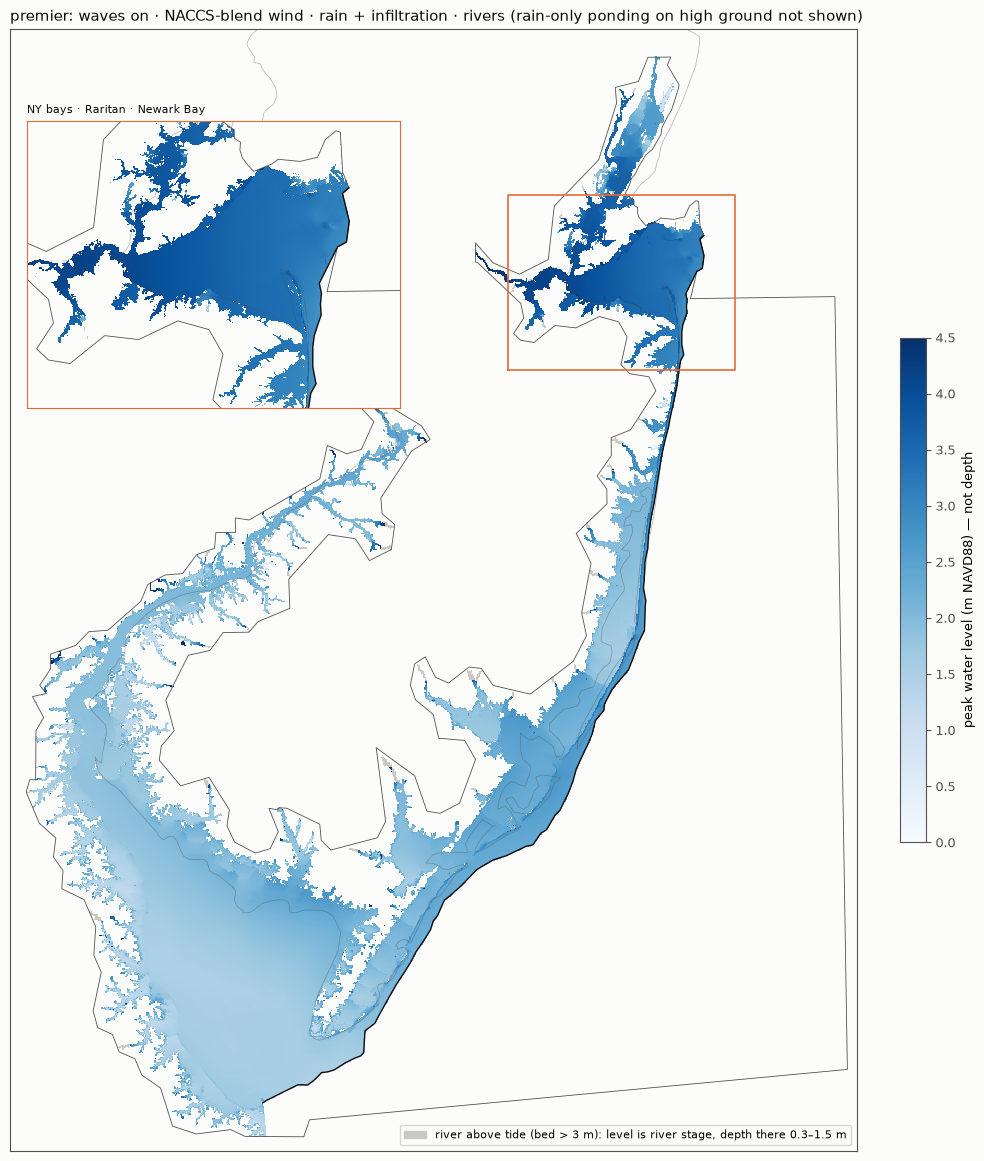

In [3]:
zs = peak_sea(PREMIER)
river = np.isfinite(zs) & (ZMIN >= 3.0)  # non-tidal reaches: the level is river stage, not surge
sea = np.where(river, np.nan, zs)
fig, ax = plt.subplots(figsize=(10, 11.5), constrained_layout=True)
grey = ListedColormap([GREY])
img, ext = binned(FX, FY, sea, 250.0)
rimg, _ = binned(FX, FY, np.where(river, 1.0, np.nan), 250.0)
ax.imshow(rimg, extent=ext, cmap=grey, interpolation="nearest")
im = ax.imshow(img, extent=ext, cmap="Blues", vmin=0, vmax=4.5, interpolation="nearest")
frame(ax)
x0, x1, y0, y1 = NYB
ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=ORANGE, lw=1.2)
ins = ax.inset_axes([0.02, 0.60, 0.44, 0.38])
img2, ext2 = binned(FX, FY, sea, 60.0, win=NYB)
rimg2, _ = binned(FX, FY, np.where(river, 1.0, np.nan), 60.0, win=NYB)
ins.imshow(rimg2, extent=ext2, cmap=grey, interpolation="nearest")
ins.imshow(img2, extent=ext2, cmap="Blues", vmin=0, vmax=4.5, interpolation="nearest")
frame(ins, win=NYB)
for s in ins.spines.values():
    s.set_edgecolor(ORANGE)
ins.set_title("NY bays · Raritan · Newark Bay", fontsize=8, loc="left", color=INK)
fig.colorbar(im, ax=ax, shrink=0.45, label="peak water level (m NAVD88) — not depth")
ax.legend(handles=[Patch(color=GREY, label="river above tide (bed > 3 m): level is river stage, "
                                           "depth there 0.3–1.5 m")],
          loc="lower right", fontsize=8, facecolor=SURFACE)
ax.set_title("premier: waves on · NACCS-blend wind · rain + infiltration · rivers "
             "(rain-only ponding on high ground not shown)",
             loc="left", color=INK);


## High-water marks — model vs observed

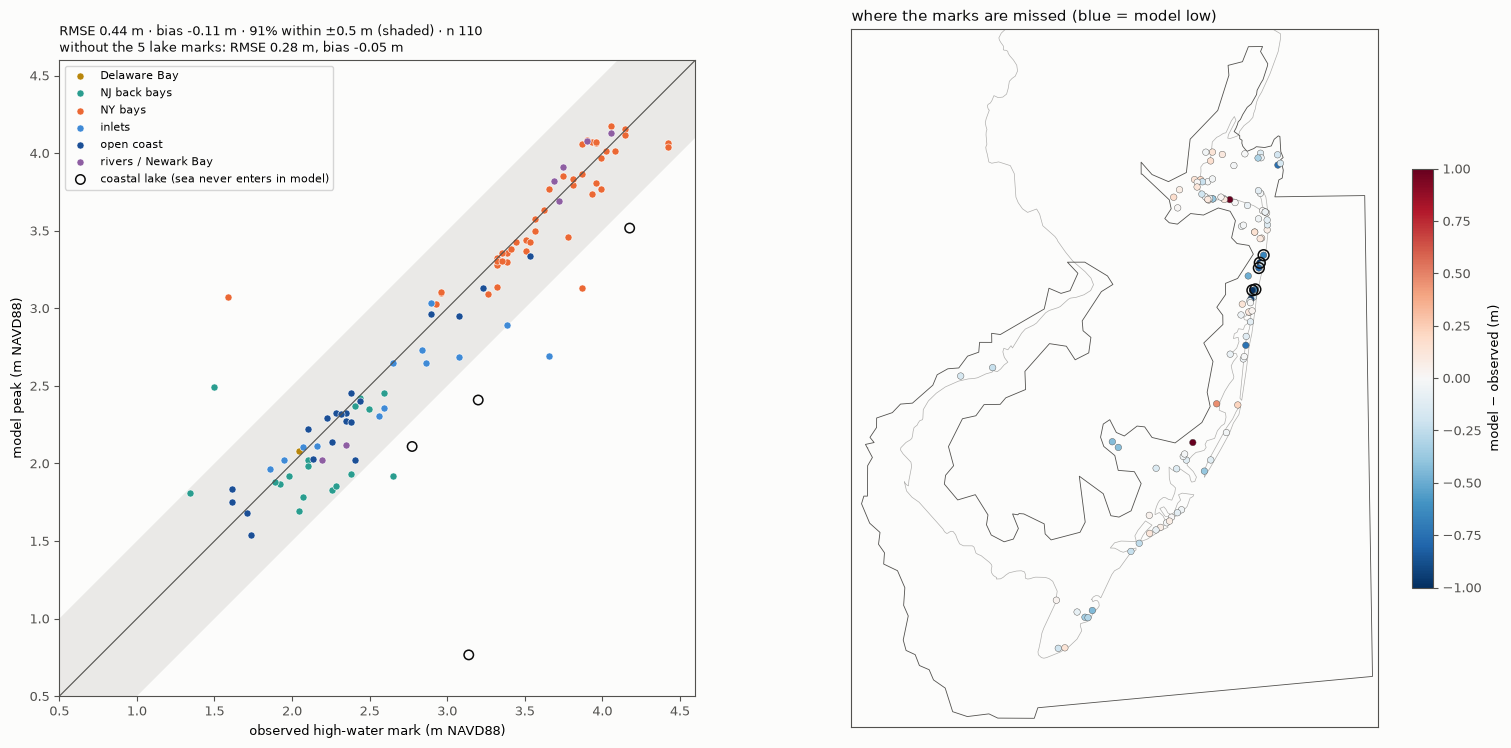

In [4]:
m = marks("rfw_on")  # = naccs-premier (run as wind-naccs+naccs-premier, renamed 10-11)
m["group"] = m["basin"].map(GROUP_OF).fillna("other")
lake = m.index.isin(LAKE_MARKS)
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 7.5), constrained_layout=True,
                           gridspec_kw={"width_ratios": [1, 1.05]})
lo, hi = 0.5, 4.6
a.plot([lo, hi], [lo, hi], color=INK_2, lw=0.8)
a.fill_between([lo, hi], [lo - 0.5, hi - 0.5], [lo + 0.5, hi + 0.5], color=GREY, alpha=0.35, lw=0)
for grp, d in m[~lake].groupby("group"):
    a.scatter(d["elev_m"], d["model_m"], s=26, color=GROUP_COLOR.get(grp, GREY), label=grp,
              edgecolor="white", lw=0.4)
a.scatter(m.loc[lake, "elev_m"], m.loc[lake, "model_m"], s=46, facecolor="none",
          edgecolor=INK, lw=1.1, label="coastal lake (sea never enters in model)")
a.set_xlim(lo, hi); a.set_ylim(lo, hi); a.set_aspect(1)
a.set_xlabel("observed high-water mark (m NAVD88)"); a.set_ylabel("model peak (m NAVD88)")
a.legend(loc="upper left", fontsize=8, facecolor=SURFACE)
r = m["resid_m"]
a.set_title(f"RMSE {rmse(r):.2f} m · bias {r.mean():+.2f} m · "
            f"{(r.abs() <= 0.5).mean():.0%} within ±0.5 m (shaded) · n {len(r)}\n"
            f"without the {lake.sum()} lake marks: RMSE {rmse(r[~lake]):.2f} m, bias {r[~lake].mean():+.2f} m",
            loc="left", color=INK, fontsize=9)

frame(b, line=False)
sc = b.scatter(m["x"], m["y"], c=m["resid_m"], cmap="RdBu_r", norm=TwoSlopeNorm(0, -1.0, 1.0),
               s=22, edgecolor=INK_2, lw=0.3, zorder=5)
b.scatter(m.loc[lake, "x"], m.loc[lake, "y"], s=60, facecolor="none", edgecolor=INK, lw=1.1, zorder=6)
fig.colorbar(sc, ax=b, shrink=0.6, label="model − observed (m)")
b.set_title("where the marks are missed (blue = model low)", loc="left", color=INK);


## Flood extent vs FEMA MOTF

MOTF scored over NJ land only; 2,047 km² of NY/DE/PA ground excluded (the MOTF sheet renders it dry). metrics.csv: CSI 0.728 · POD 0.847 · FAR 0.162


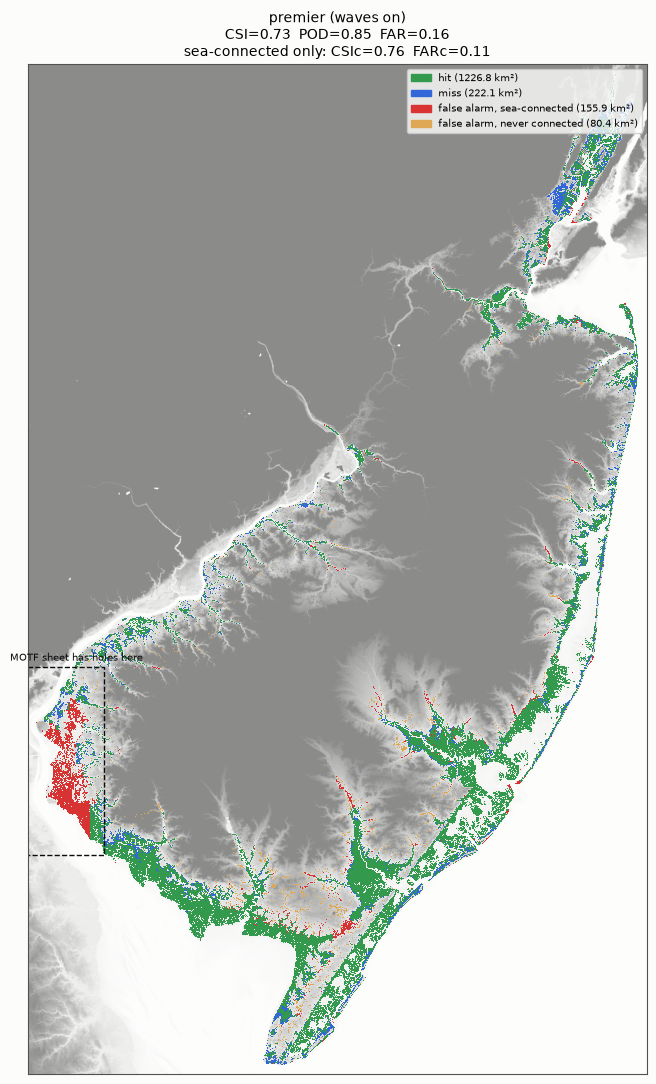

In [5]:
fig, axes = plots.plot_motf_panels({"premier (waves on)": PREMIER}, split_fa=True, ncol=1)
fig.set_size_inches(9, 12)
SALEM_GAP = (445_000, 466_300, 4_356_500, 4_399_000)  # MOTF sheet: rectangular holes, no data
for ax in np.ravel(axes):
    ax.set_xticks([]); ax.set_yticks([])
    x0, x1, y0, y1 = SALEM_GAP
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=INK, lw=1.0, ls="--")
    ax.text(x0, y1 + 1500, "MOTF sheet has holes here", fontsize=7, color=INK)
print(f"MOTF scored over NJ land only; {P['motf_km2_excluded_boxes']:,.0f} km² of NY/DE/PA ground excluded "
      f"(the MOTF sheet renders it dry). metrics.csv: CSI {P['motf_csi']:.3f} · POD {P['motf_pod']:.3f} · "
      f"FAR {P['motf_far']:.3f}")


## Gauges across the domain

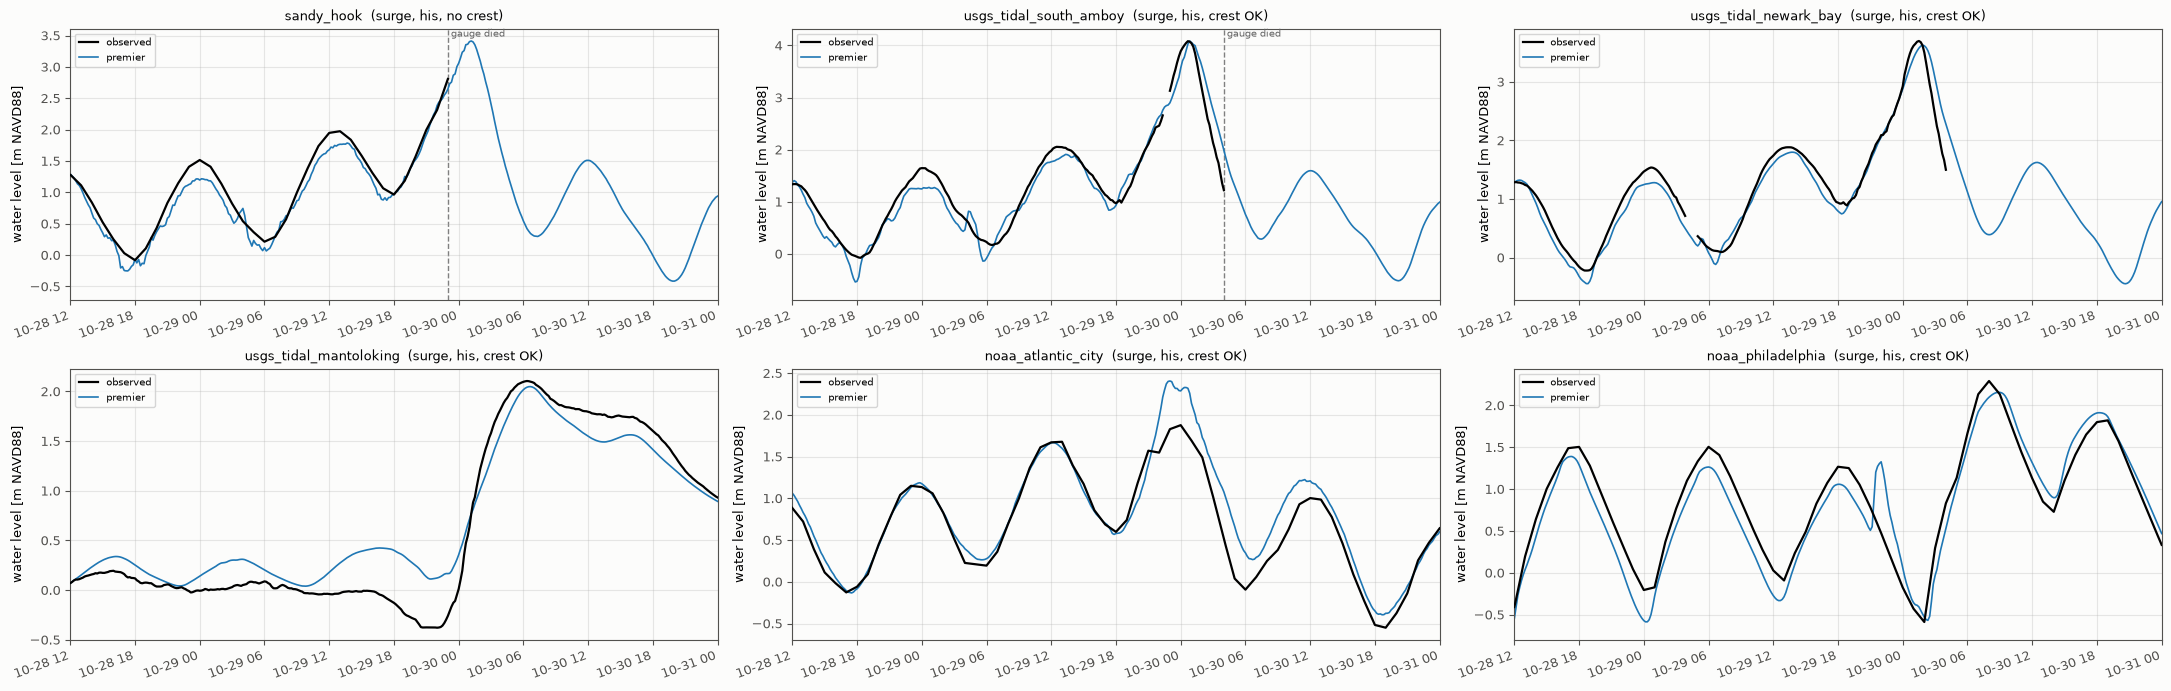

In [6]:
fig, axes = plots.plot_gauge_verification({"premier": PREMIER}, names=['sandy_hook', 'usgs_tidal_south_amboy', 'usgs_tidal_newark_bay', 'usgs_tidal_mantoloking', 'noaa_atlantic_city', 'noaa_philadelphia'], ncol=3)
fig.suptitle("")
for ax in axes.ravel():
    ax.set_xlim(pd.Timestamp("2012-10-28 12:00"), pd.Timestamp("2012-10-31 00:00"))


## Delaware gauges — ERA5 vs NACCS-blend wind

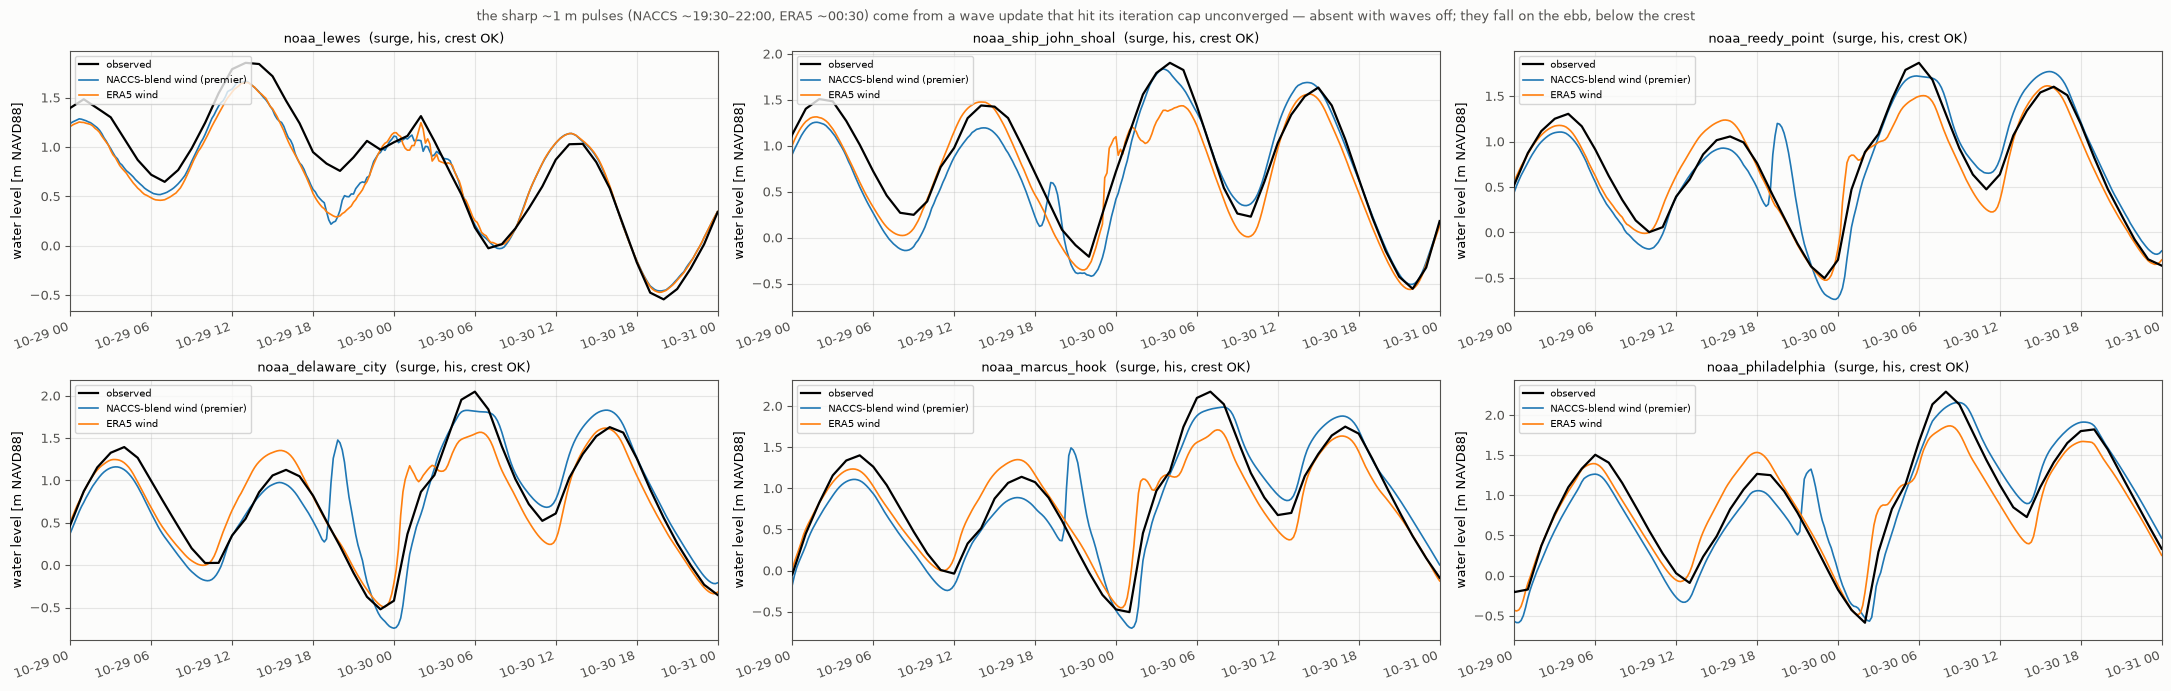

In [7]:
fig, axes = plots.plot_gauge_verification(
    {"NACCS-blend wind (premier)": PREMIER, "ERA5 wind": ERA5}, names=['noaa_lewes', 'noaa_ship_john_shoal', 'noaa_reedy_point', 'noaa_delaware_city', 'noaa_marcus_hook', 'noaa_philadelphia'], ncol=3)
fig.suptitle("the sharp ~1 m pulses (NACCS ~19:30–22:00, ERA5 ~00:30) come from a wave update that hit its "
             "iteration cap unconverged — absent with waves off; they fall on the ebb, below the crest",
             fontsize=9, color=INK_2)
for ax in axes.ravel():
    ax.set_xlim(pd.Timestamp("2012-10-29 00:00"), pd.Timestamp("2012-10-31 00:00"))


## Where waves raise the peak

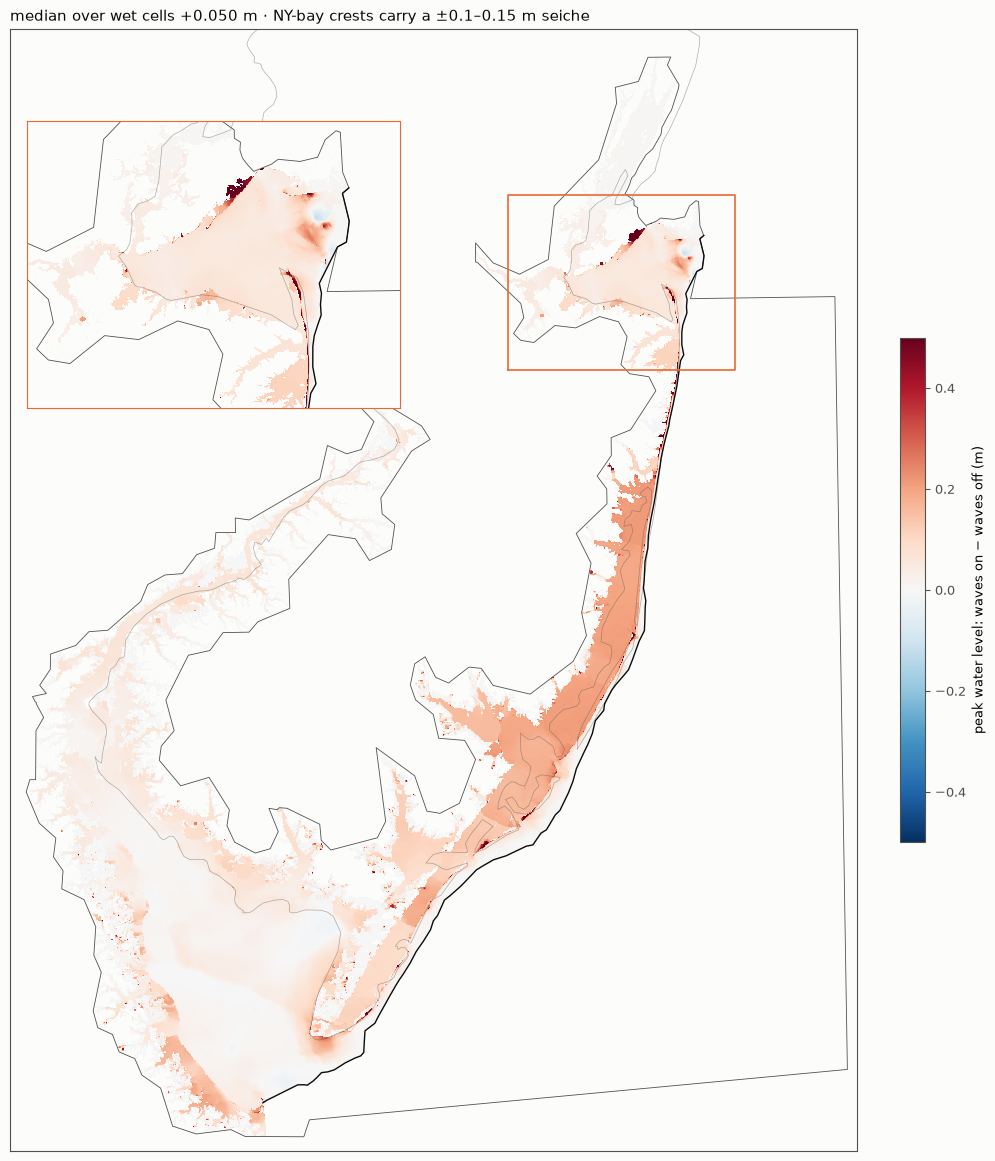

In [8]:
on, off = peak(PREMIER), peak(TWIN)
both = np.isfinite(on) & np.isfinite(off)
d = np.where(both, on - off, np.nan)
fig, ax = plt.subplots(figsize=(10, 11.5), constrained_layout=True)
img, ext = binned(FX, FY, d, 250.0, how="median")
im = ax.imshow(img, extent=ext, cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.5, 0.5), interpolation="nearest")
frame(ax)
x0, x1, y0, y1 = NYB
ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=ORANGE, lw=1.2)
ins = ax.inset_axes([0.02, 0.60, 0.44, 0.38])
img2, ext2 = binned(FX, FY, d, 60.0, win=NYB, how="median")
ins.imshow(img2, extent=ext2, cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.5, 0.5), interpolation="nearest")
frame(ins, win=NYB)
for s in ins.spines.values():
    s.set_edgecolor(ORANGE)
fig.colorbar(im, ax=ax, shrink=0.45, label="peak water level: waves on − waves off (m)")
ax.set_title(f"median over wet cells {np.nanmedian(d):+.3f} m · NY-bay crests carry a ±0.1–0.15 m seiche",
             loc="left", color=INK);


## What each step bought — HWM RMSE

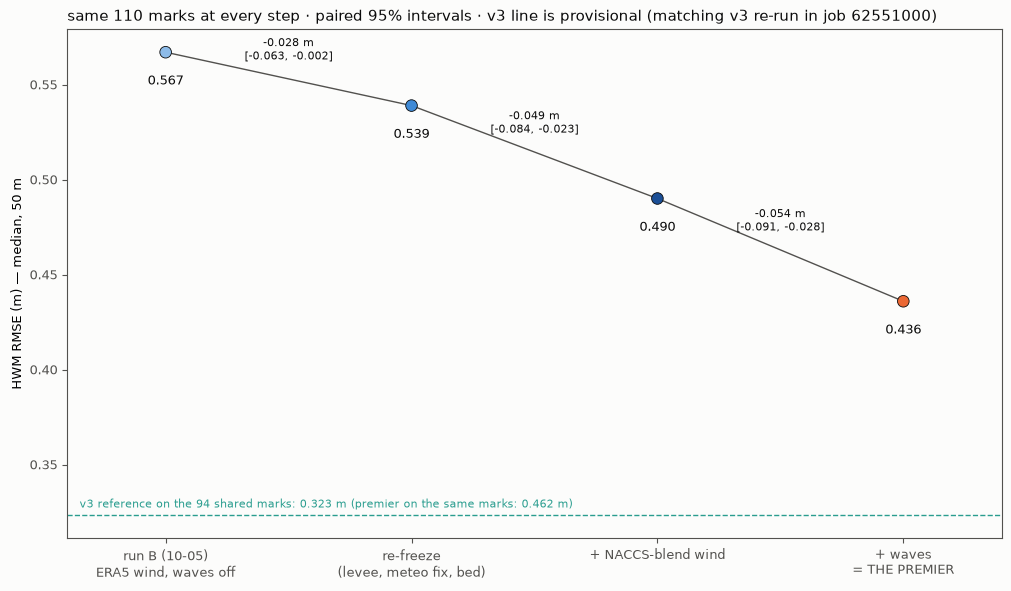

In [9]:
steps = [("run B (10-05)\nERA5 wind, waves off", "B_off"),
         ("re-freeze\n(levee, meteo fix, bed)", "rf_off"),
         ("+ NACCS-blend wind", "rfw_off"),
         ("+ waves\n= THE PREMIER", "rfw_on")]
R = {lab: marks(lab)["resid_m"] for _, lab in steps}
common = sorted(set.intersection(*(set(r.index) for r in R.values())))
vals = [rmse(R[lab].loc[common]) for _, lab in steps]
fig, ax = plt.subplots(figsize=(10, 5.8), constrained_layout=True)
xs = np.arange(len(steps))
ax.plot(xs, vals, color=INK_2, lw=1, zorder=1)
ax.scatter(xs, vals, s=70, color=["#8dbbe8", "#3f8ad6", "#1b4f96", ORANGE], zorder=3,
           edgecolor=INK, lw=0.6)
for i in range(1, len(steps)):
    dlt, lo_, hi_ = paired_ci(R[steps[i][1]].loc[common], R[steps[i - 1][1]].loc[common])
    ax.annotate(f"{dlt:+.3f} m\n[{lo_:+.3f}, {hi_:+.3f}]", ((xs[i] + xs[i - 1]) / 2, (vals[i] + vals[i - 1]) / 2),
                textcoords="offset points", xytext=(0, 14), ha="center", fontsize=8, color=INK)
for x, v in zip(xs, vals):
    ax.text(x, v - 0.012, f"{v:.3f}", ha="center", va="top", fontsize=9, color=INK)
# v3 reference on the marks BOTH domains score (v3 = 10-05 shared-fix re-run, waves on)
v3 = marks("v3fix_on")["resid_m"]
sh = sorted(set(v3.index) & set(R["rfw_on"].index))
v3_r, pr_r = rmse(v3.loc[sh]), rmse(R["rfw_on"].loc[sh])
ax.axhline(v3_r, color="#2a9d8f", ls="--", lw=1)
ax.text(-0.35, v3_r + 0.004, f"v3 reference on the {len(sh)} shared marks: {v3_r:.3f} m "
        f"(premier on the same marks: {pr_r:.3f} m)", fontsize=8, color="#2a9d8f")
ax.set_xticks(xs, [s for s, _ in steps])
ax.set_ylabel("HWM RMSE (m) — median, 50 m")
ax.set_xlim(-0.4, len(steps) - 0.6)
ax.set_title(f"same {len(common)} marks at every step · paired 95% intervals · "
             "v3 line is provisional (matching v3 re-run in job 62551000)", loc="left", color=INK);
